# 03 — Factor correlation and factor selection

Constructs factor returns, evaluates collinearity and stability, builds AI baskets, and reports staged explanatory power.

Reusable implementation and configuration: `src/factor_lens/factor_correlation.py`.


In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve()
while project_root != project_root.parent and not (project_root / "src" / "factor_lens").exists():
    project_root = project_root.parent
if not (project_root / "src" / "factor_lens").exists():
    raise RuntimeError("Open this notebook from the repository root or a subfolder.")
sys.path.insert(0, str(project_root / "src"))


Computing factor analysis ...
Saved to factor_lens_local\factors\factors_v1__clean_v1__yahoo_2016-01-01_2026-10-01_v1


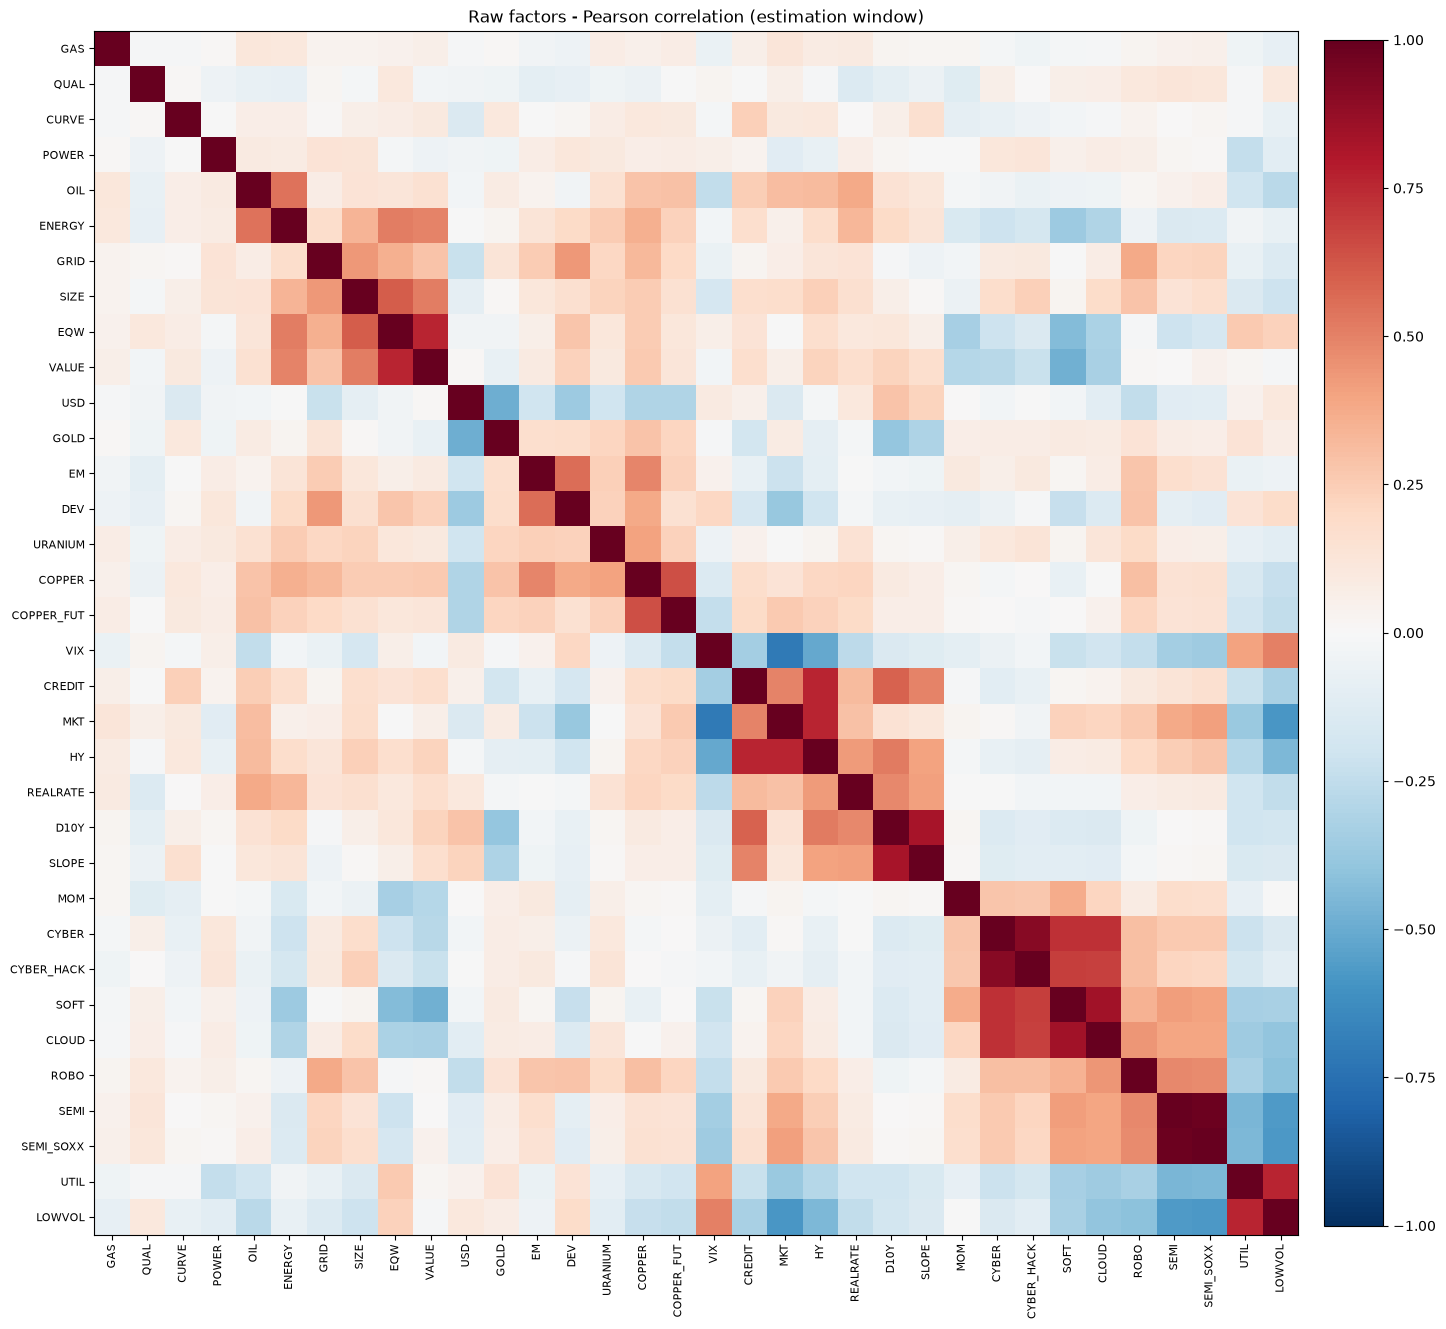

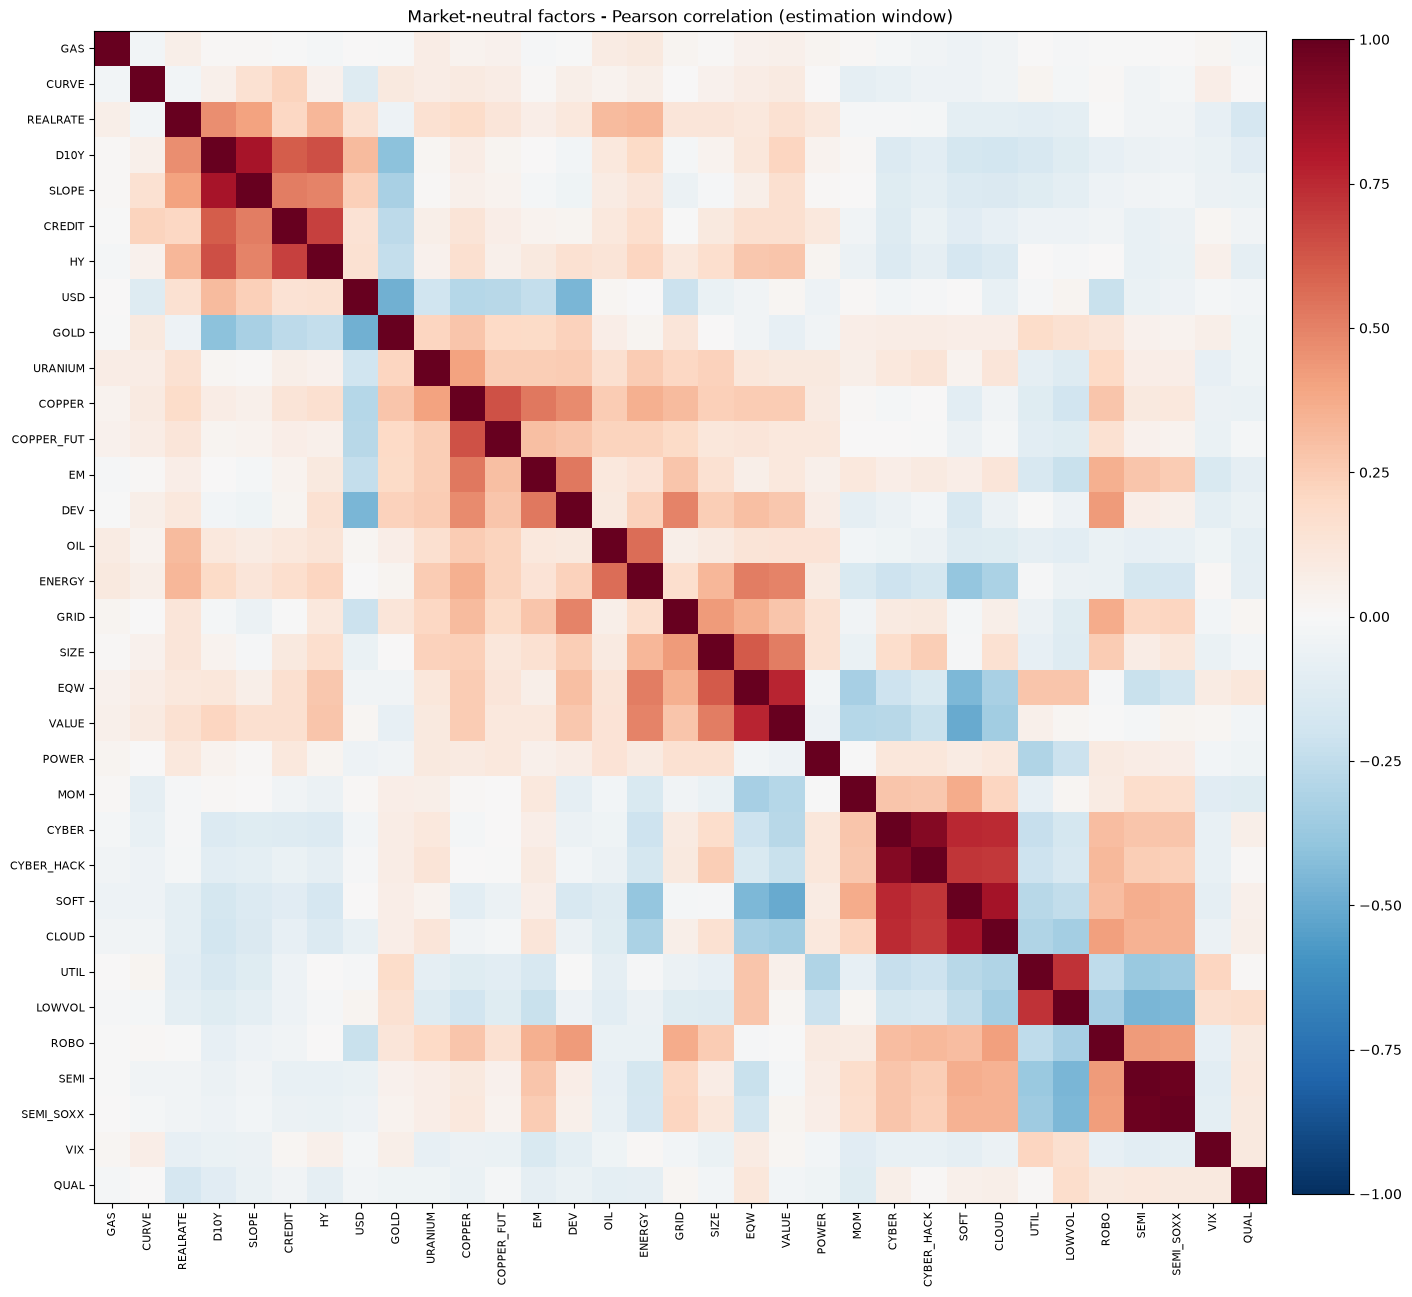

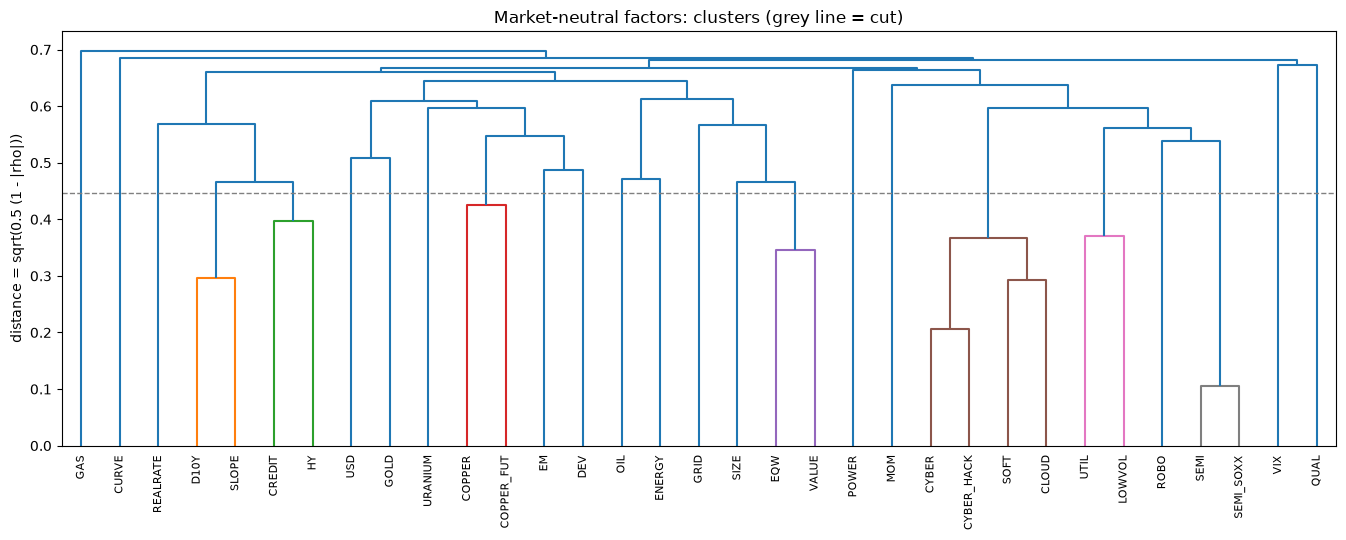

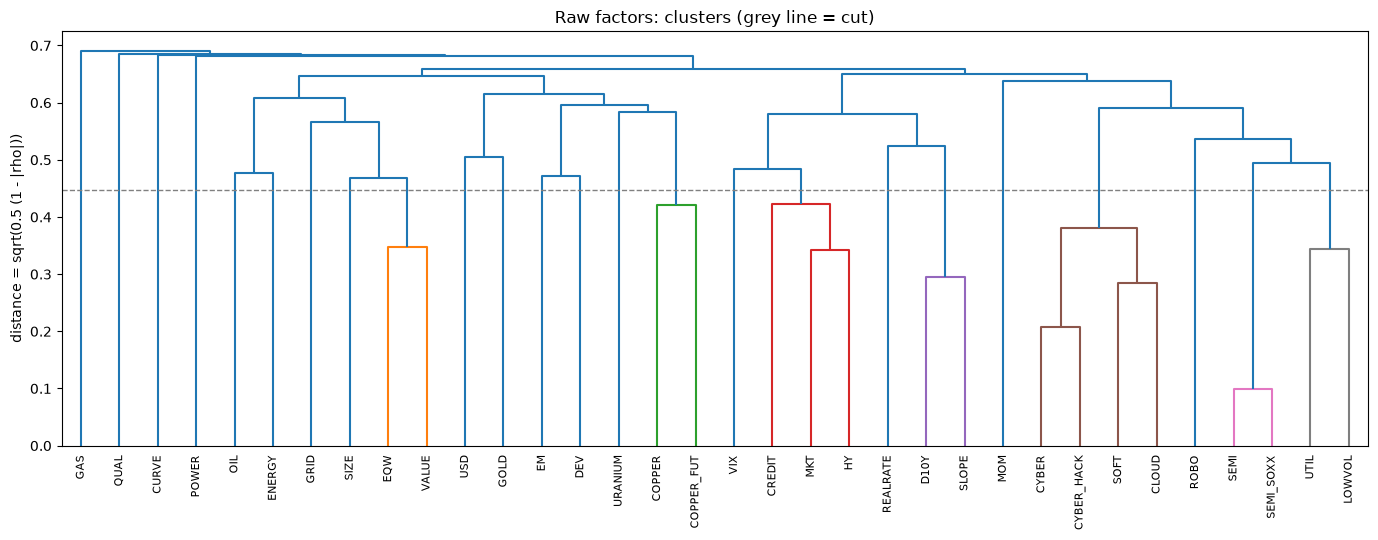

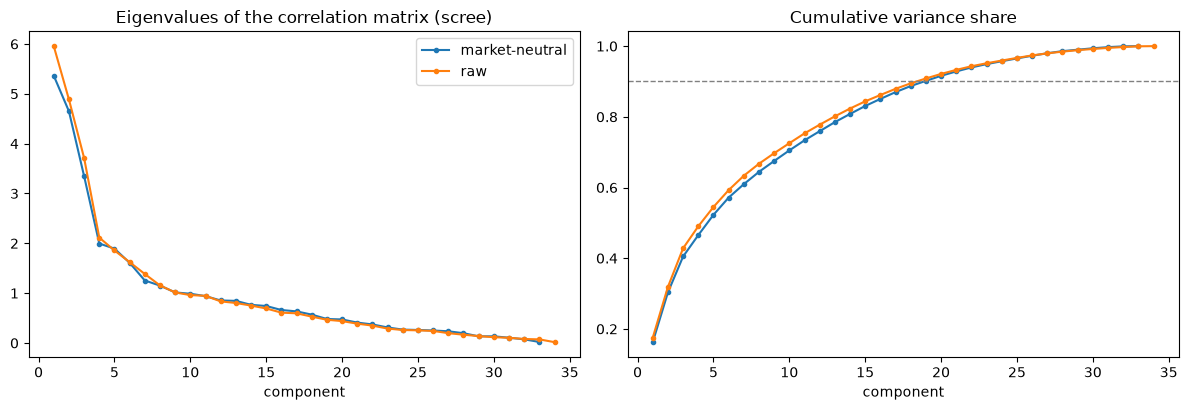

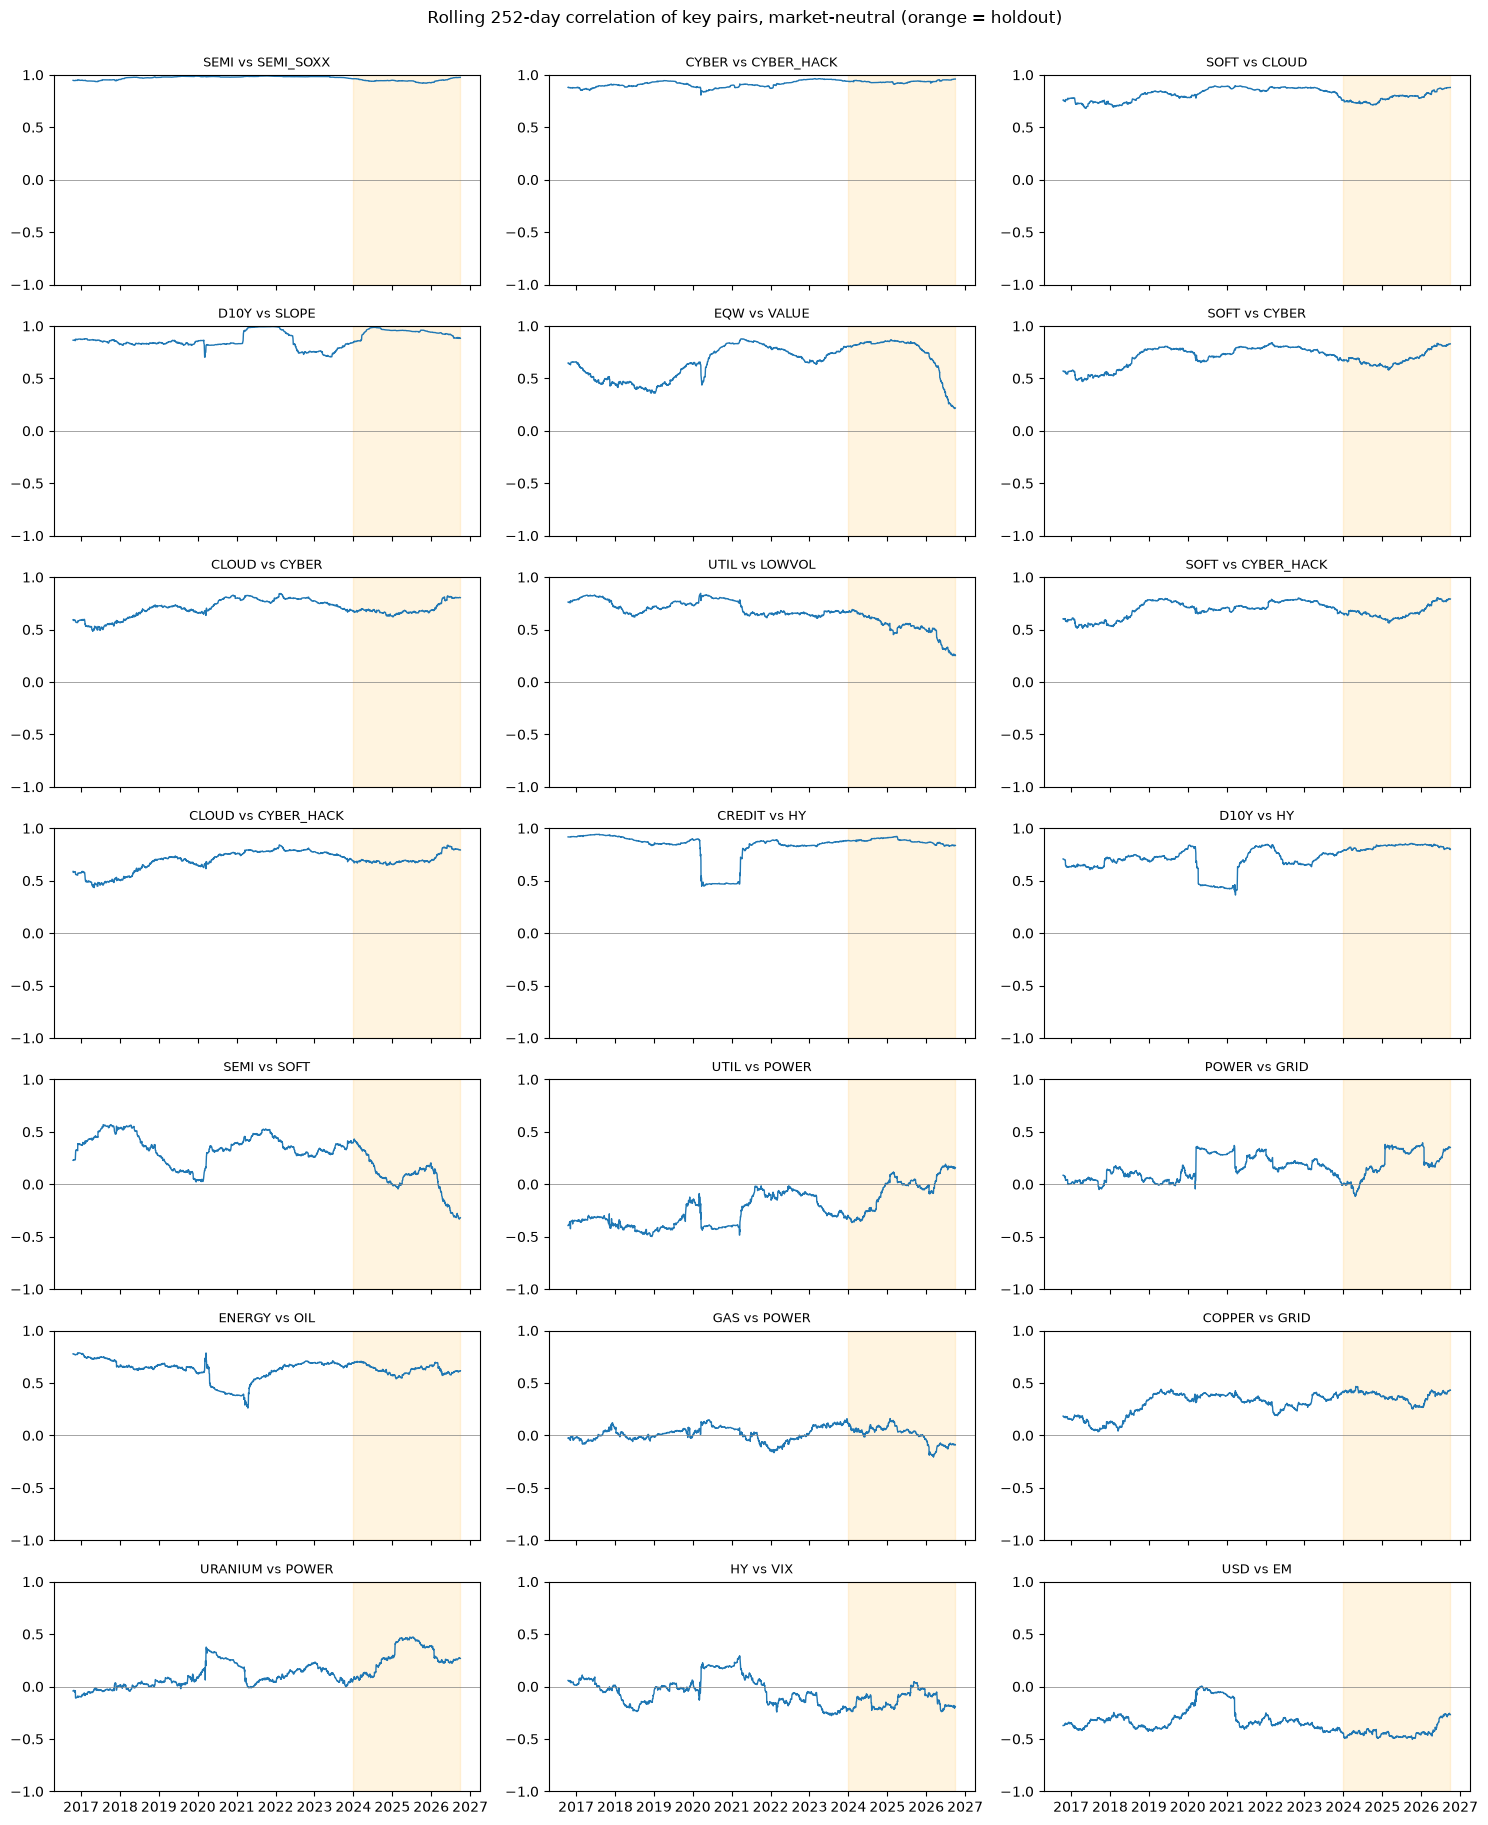

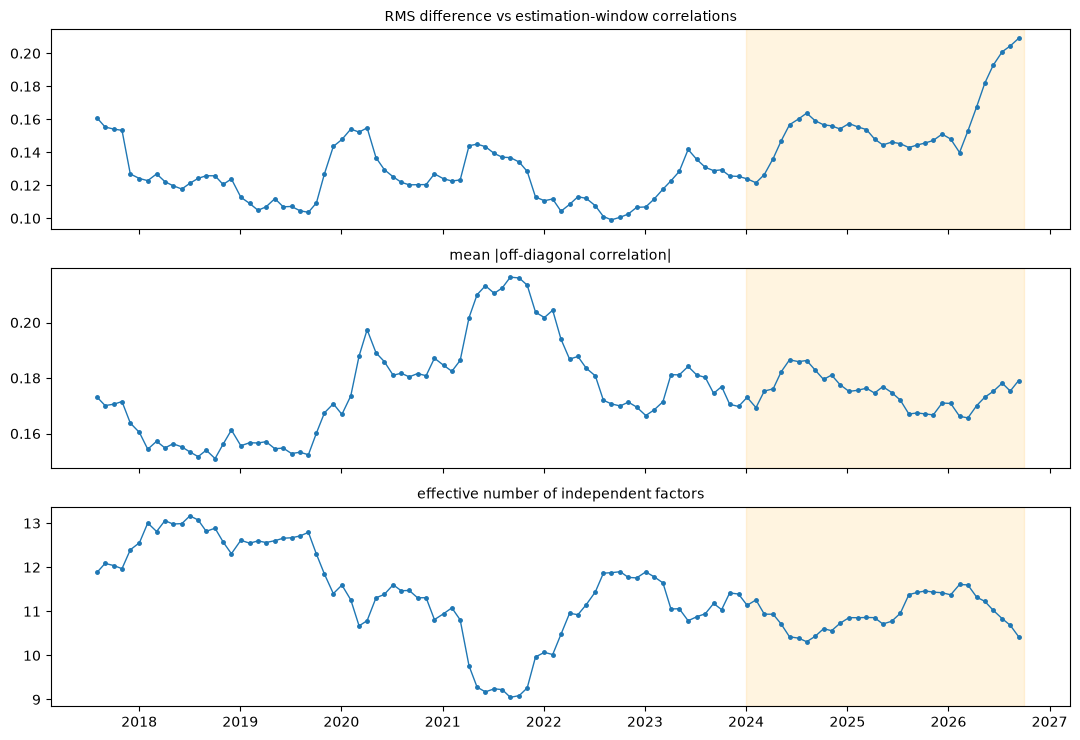

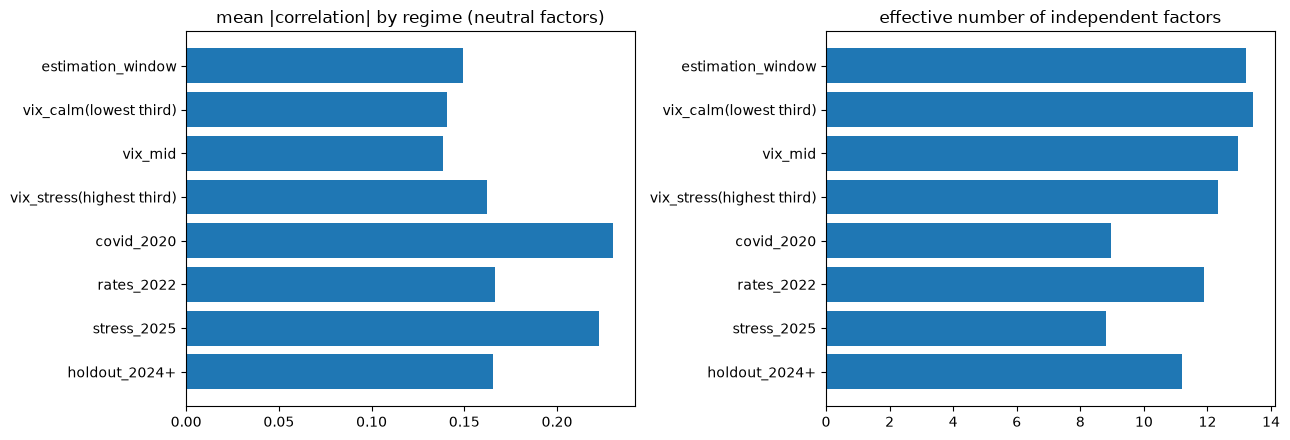

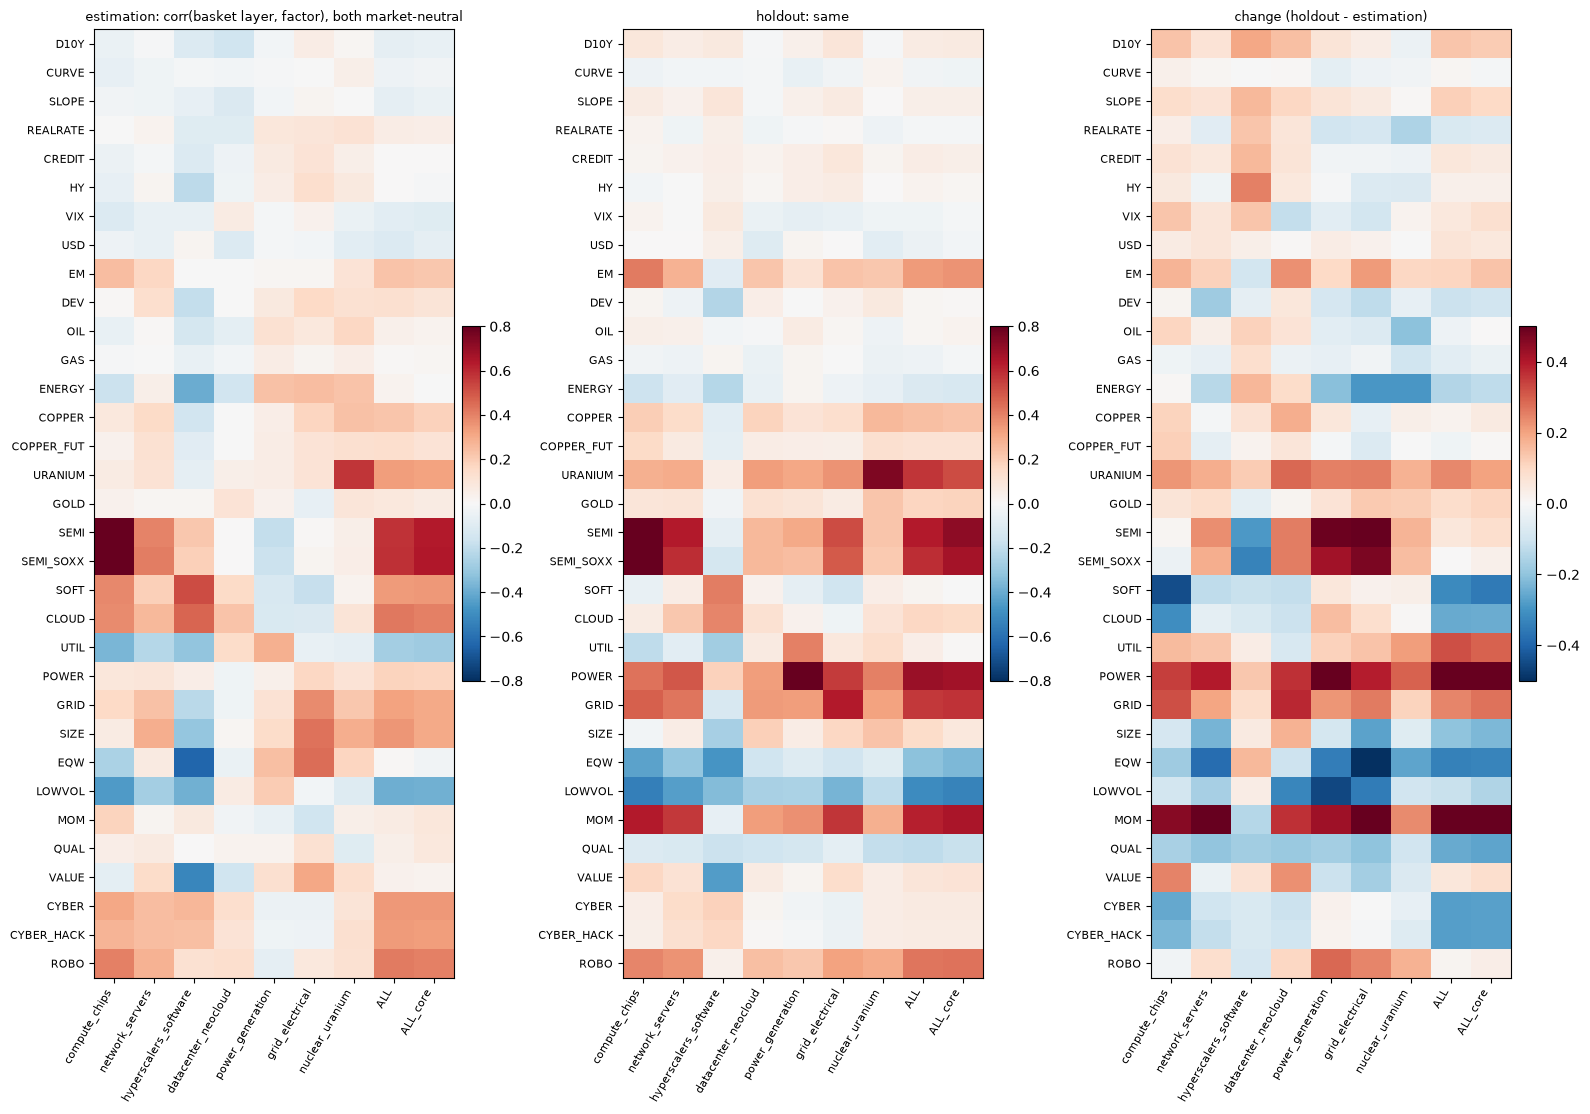

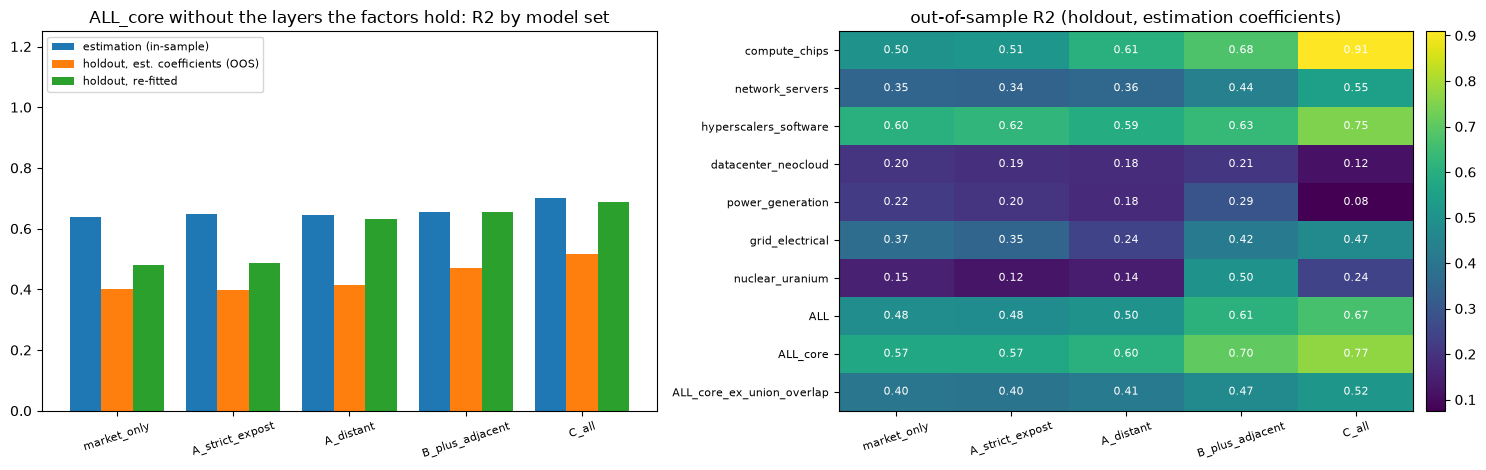

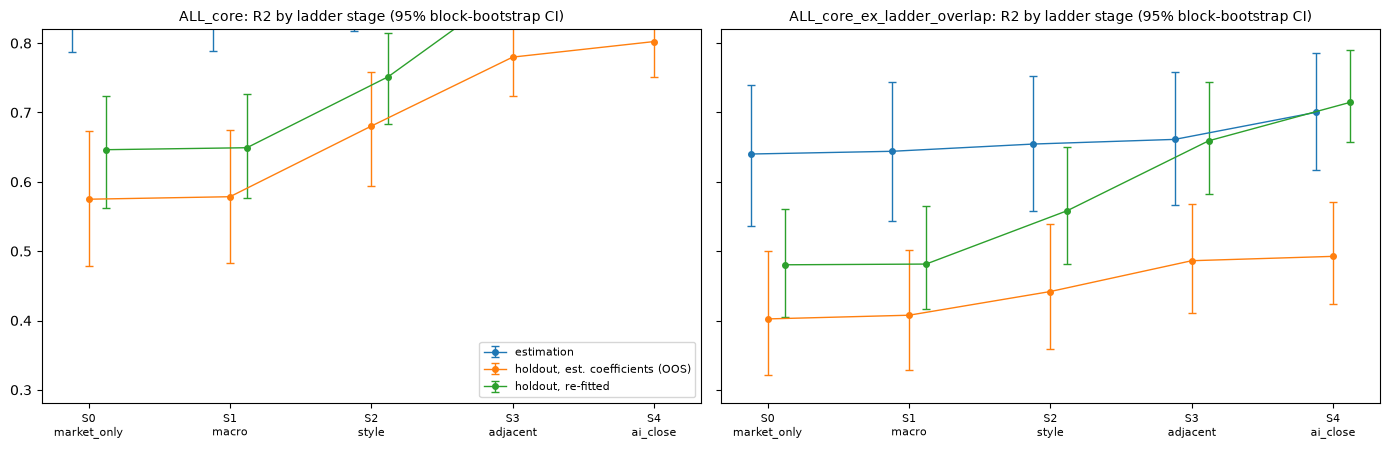

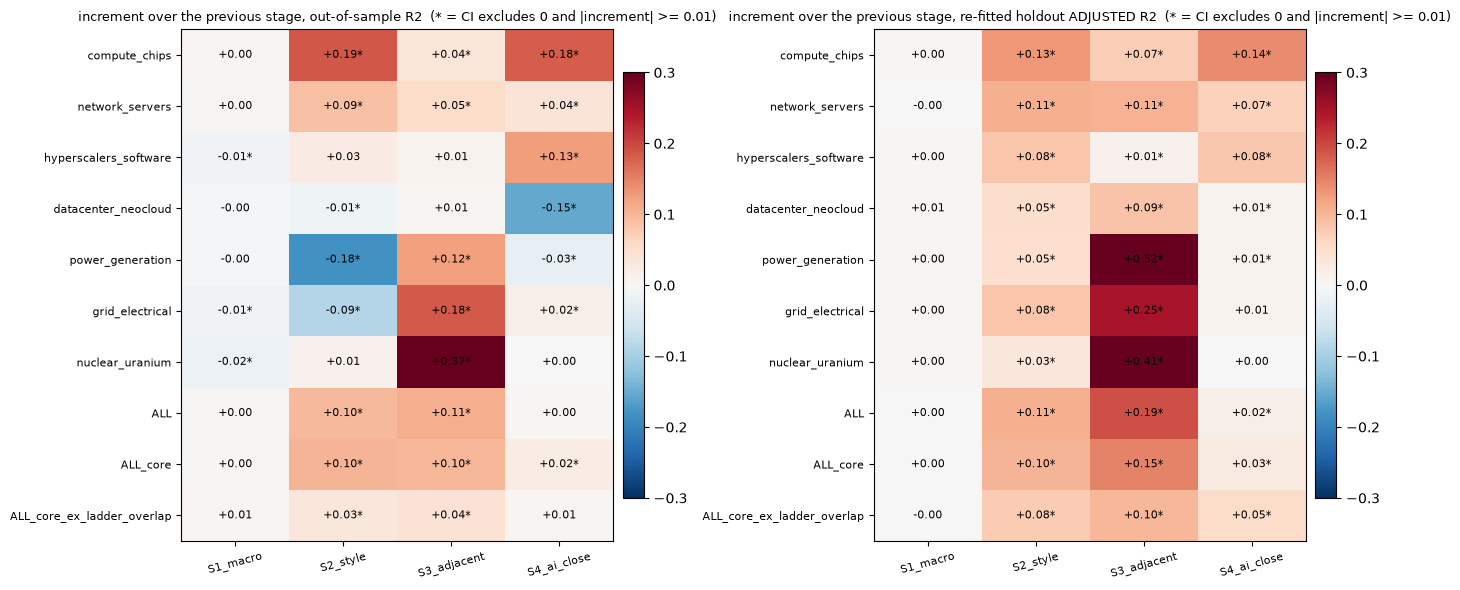

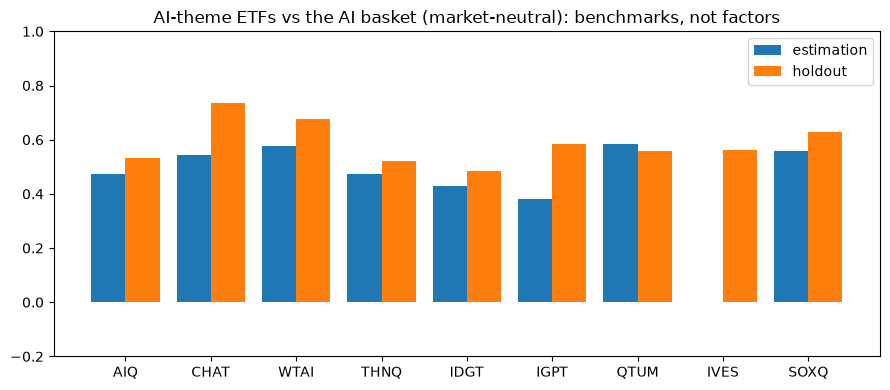

Estimation window 2017-01-03 -> 2023-12-29 (1760 days) | holdout 2024-01-02 -> 2026-10-01 (690 days)
Candidates 38 | eligible 34 | complete rows used: raw 1748, neutral 1748

=== 1. EXCLUDED CANDIDATES (and why) ===
          name         bucket first_valid  est_coverage                                                                reason
URANIUM_MINERS Metals/nuclear  2019-12-05      0.581818 starts 2019-12-05 after window start 2017-01-03; coverage 58.2% < 98%
     SEMI_SOXQ Semiconductors  2021-06-14      0.364773 starts 2021-06-14 after window start 2017-01-03; coverage 36.5% < 98%
         INFRA Software/cloud  2018-05-17      0.803977 starts 2018-05-17 after window start 2017-01-03; coverage 80.4% < 98%
         CAPEX     Grid/capex  2017-03-09      0.974432 starts 2017-03-09 after window start 2017-01-03; coverage 97.4% < 98%

=== 2. DESCRIPTIVES (estimation window; beta_to_mkt and r2_mkt show how much each factor is the market) ===
    factor  mean_ann  vol_ann   skew  ex_kurt

In [2]:
from factor_lens import factor_correlation as pipeline

res = pipeline.get_results()
pipeline.make_figures(res)
pipeline.print_report(res)


## Visual summary

The chart below shows how successive factor blocks add out-of-sample explanatory power across the basket layers.


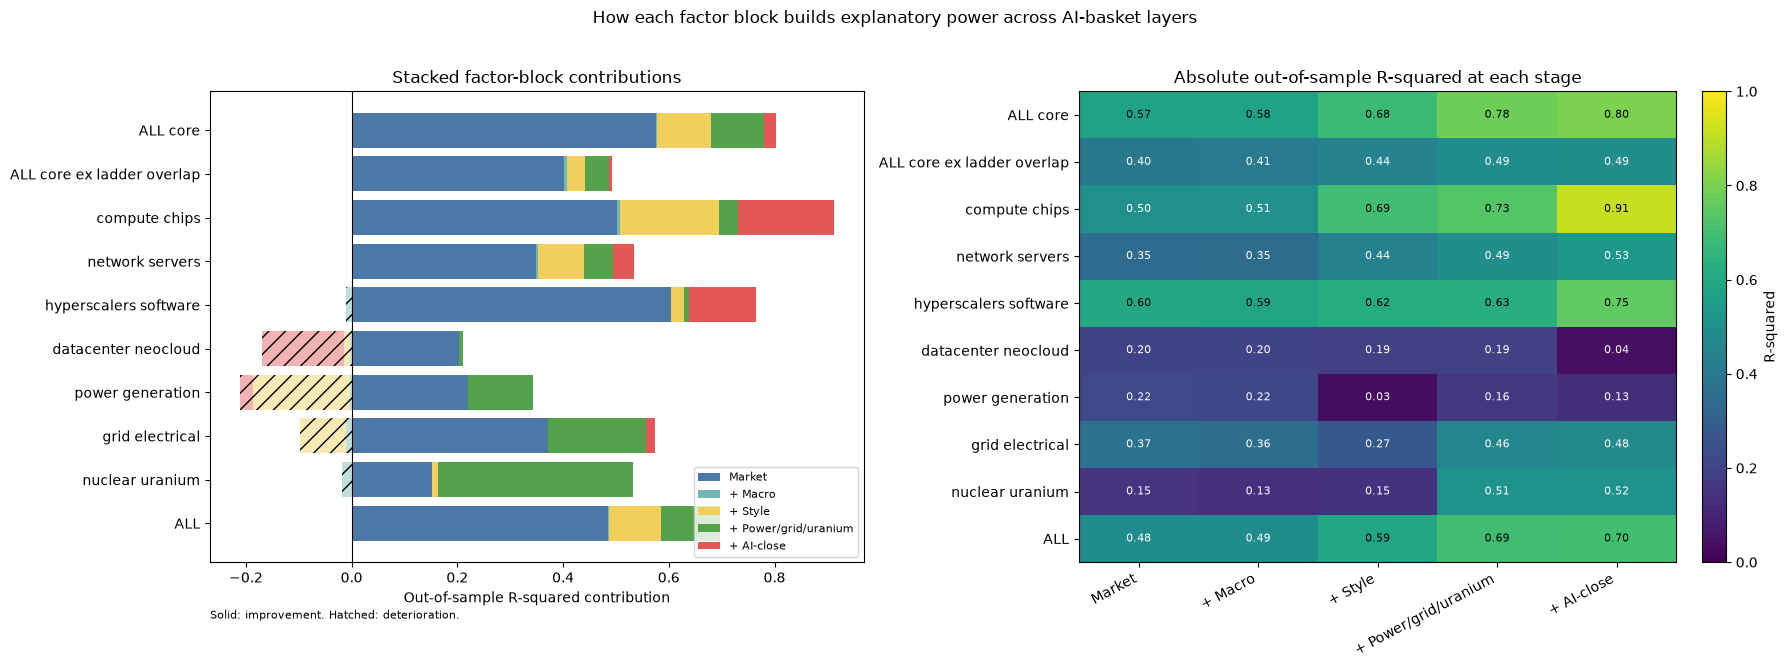

stage,S0_market_only,S1_macro,S2_style,S3_adjacent,S4_ai_close
basket,,,,,
ALL_core,0.575,0.004,0.102,0.099,0.022
ALL_core_ex_ladder_overlap,0.402,0.005,0.034,0.044,0.006
compute_chips,0.503,0.005,0.187,0.036,0.182
network_servers,0.348,0.003,0.088,0.055,0.039
hyperscalers_software,0.604,-0.011,0.025,0.010,0.126
datacenter_neocloud,0.203,-0.003,-0.012,0.007,-0.154
power_generation,0.221,-0.004,-0.182,0.123,-0.025
grid_electrical,0.372,-0.011,-0.087,0.184,0.017
nuclear_uranium,0.152,-0.017,0.012,0.368,0.001


In [3]:
r2_oos_by_stage, r2_oos_increment = pipeline.plot_ladder_r2_stack(res)
display(r2_oos_increment.round(3))
